In [18]:

import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:     ", keras.__version__)


TensorFlow version: 2.21.0
Keras version:      3.13.2


In [19]:
from tensorflow.keras import layers
from tensorflow.keras.datasets import imdb

import numpy as np
import random

# ----------------------- Settings (change these and re-run to experiment!) -----------------------
VOCAB_SIZE = 10000   # number of distinct words we keep
MAX_LEN = 200        # every review is padded / truncated to 200 words
EMBEDDING_DIM = 32   # size of the vector each word is turned into
BATCH_SIZE = 128     # how many reviews the model sees before updating weights
EPOCHS = 10           # how many full passes over the training data

# Reproducibility: fix the random seeds
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)


In [20]:

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Training reviews:", len(x_train), "| Test reviews:", len(x_test))
print("Training labels :", len(y_train), "| Test labels :", len(y_test))
print()
print("First review (word IDs):", x_train[0][:20], "...")
print("Its label            :", y_train[0], "(1 = positive, 0 = negative)")
print()
print("Length of review 1:", len(x_train[0]), "words")
print("Length of review 2:", len(x_train[1]), "words  <- reviews have different lengths!")

# Decode one review back to English so we can see what the data really looks like.
word_index = imdb.get_word_index()                 # dict: word -> integer ID
reverse_word_index = {value: key for key, value in word_index.items()}

def decode_review(encoded_review):

    return " ".join(reverse_word_index.get(i - 3, "?") for i in encoded_review)

print()
print("Decoded review 1:")
print(decode_review(x_train[0]))


Training reviews: 25000 | Test reviews: 25000
Training labels : 25000 | Test labels : 25000

First review (word IDs): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25] ...
Its label            : 1 (1 = positive, 0 = negative)

Length of review 1: 218 words
Length of review 2: 189 words  <- reviews have different lengths!

Decoded review 1:
? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you

In [21]:
from tensorflow.keras.utils import pad_sequences

x_train = pad_sequences(x_train, maxlen=MAX_LEN, padding='post', truncating='post')
x_test  = pad_sequences(x_test,  maxlen=MAX_LEN, padding='post', truncating='post')

print("After padding:")
print("x_train shape:", x_train.shape)   # (25000, 200) -> 25,000 reviews of 200 words each
print("x_test  shape:", x_test.shape)
print()
print("Start of padded review 2:", x_test[1][:20])
print("End of padded review 2  :", x_test[1][-20:])   # zeros = padding


After padding:
x_train shape: (25000, 200)
x_test  shape: (25000, 200)

Start of padded review 2: [   1   14   22 3443    6  176    7 5063   88   12 2679   23 1310    5
  109  943    4  114    9   55]
End of padded review 2  : [1669  398  229   10   10   13 2822  670 5304   14    9   31    7   27
  111  108   15 2033   19 7836]


In [22]:
# Build the SimpleRNN model.
model_rnn = keras.Sequential([
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    layers.SimpleRNN(32),          # 32 memory units; returns only the final memory
    #layers.SimpleRNN(64),
    layers.Dense(1, activation='sigmoid')   # one output: P(positive review)
])

model_rnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:
model_rnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# ModelCheckpoint saves the best version of the model (best validation accuracy)
# automatically during training — a habit worth building from day one.
checkpoint_rnn = keras.callbacks.ModelCheckpoint(
    'rnn_best.keras', monitor='val_accuracy', save_best_only=True, verbose=1
)

history_rnn = model_rnn.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=[checkpoint_rnn],
    verbose=1
)


Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4928 - loss: 0.6950
Epoch 1: val_accuracy improved from None to 0.49980, saving model to rnn_best.keras

Epoch 1: finished saving model to rnn_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.4998 - loss: 0.6942 - val_accuracy: 0.4998 - val_loss: 0.6938
Epoch 2/10
154/157 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6321 - loss: 0.6528
Epoch 2: val_accuracy improved from 0.49980 to 0.52240, saving model to rnn_best.keras

Epoch 2: finished saving model to rnn_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6136 - loss: 0.6474 - val_accuracy: 0.5224 - val_loss: 0.7017
Epoch 3/10
154/157 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7055 - loss: 0.5461
Epoch 3: val_accuracy did not improve from 0.52240
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7046 - loss: 0.5309 - val_accuracy: 0.5098 - val_loss: 0.7639
Epoch 4/10
155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy

In [24]:
loss_rnn, acc_rnn = model_rnn.evaluate(x_test, y_test, verbose=0)
print(f"SimpleRNN -> Test loss: {loss_rnn:.4f} | Test accuracy: {acc_rnn:.4f}")

# Predict the first 5 test reviews
probs = model_rnn.predict(x_test[:5], verbose=0).flatten()
for i, p in enumerate(probs):
    pred = "Positive" if p > 0.5 else "Negative"
    true = "Positive" if y_test[i] == 1 else "Negative"
    print(f"Review {i+1}: predicted {pred} (prob {p:.2f}) | actually {true}")


SimpleRNN -> Test loss: 1.0623 | Test accuracy: 0.4997
Review 1: predicted Negative (prob 0.38) | actually Negative
Review 2: predicted Negative (prob 0.18) | actually Positive
Review 3: predicted Negative (prob 0.07) | actually Positive
Review 4: predicted Positive (prob 0.74) | actually Negative
Review 5: predicted Negative (prob 0.38) | actually Positive


In [25]:
# 1. Save the trained model
model_rnn.save('rnn_model.keras')
print("Saved model to rnn_model.keras")

# 2. Load it back from disk
loaded_rnn = keras.models.load_model('rnn_model.keras')

# 3. Prove the loaded model works: evaluate it again
loss_loaded, acc_loaded = loaded_rnn.evaluate(x_test, y_test, verbose=0)
print(f"Original model accuracy : {acc_rnn:.4f}")
print(f"Reloaded model accuracy : {acc_loaded:.4f}  <- should match!")

# 4. (Colab tip) To download the saved file to your own computer, uncomment:
# from google.colab import files
# files.download('rnn_model.keras')


Saved model to rnn_model.keras
Original model accuracy : 0.4997
Reloaded model accuracy : 0.4997  <- should match!


In [26]:
model_lstm = keras.Sequential([
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    layers.LSTM(32),               # <-- the only change vs. Practical 1
    layers.Dense(1, activation='sigmoid')
])

model_lstm.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [27]:
model_lstm.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

checkpoint_lstm = keras.callbacks.ModelCheckpoint(
    'lstm_best.keras', monitor='val_accuracy', save_best_only=True, verbose=1
)

history_lstm = model_lstm.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=[checkpoint_lstm],
    verbose=1
)


Epoch 1/10
154/157 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5102 - loss: 0.6929
Epoch 1: val_accuracy improved from None to 0.50620, saving model to lstm_best.keras

Epoch 1: finished saving model to lstm_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.5279 - loss: 0.6924 - val_accuracy: 0.5062 - val_loss: 0.6991
Epoch 2/10
155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5106 - loss: 0.6918
Epoch 2: val_accuracy improved from 0.50620 to 0.53140, saving model to lstm_best.keras

Epoch 2: finished saving model to lstm_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.5272 - loss: 0.6905 - val_accuracy: 0.5314 - val_loss: 0.6898
Epoch 3/10
154/157 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5736 - loss: 0.6800
Epoch 3: val_accuracy improved from 0.53140 to 0.71900, saving model to lstm_best.keras

Epoch 3: finished saving model to lstm_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6103 - loss: 0.6544 - val_accurac

In [28]:
loss_lstm, acc_lstm = model_lstm.evaluate(x_test, y_test, verbose=0)
print(f"LSTM -> Test loss: {loss_lstm:.4f} | Test accuracy: {acc_lstm:.4f}")

probs = model_lstm.predict(x_test[:5], verbose=0).flatten()
for i, p in enumerate(probs):
    pred = "Positive" if p > 0.5 else "Negative"
    true = "Positive" if y_test[i] == 1 else "Negative"
    print(f"Review {i+1}: predicted {pred} (prob {p:.2f}) | actually {true}")


LSTM -> Test loss: 0.6220 | Test accuracy: 0.6324
Review 1: predicted Positive (prob 0.52) | actually Negative
Review 2: predicted Positive (prob 0.86) | actually Positive
Review 3: predicted Positive (prob 0.76) | actually Positive
Review 4: predicted Negative (prob 0.29) | actually Negative
Review 5: predicted Positive (prob 0.52) | actually Positive


In [29]:
model_lstm.save('lstm_model.keras')
loaded_lstm = keras.models.load_model('lstm_model.keras')

loss_loaded, acc_loaded = loaded_lstm.evaluate(x_test, y_test, verbose=0)
print(f"Saved & reloaded lstm_model.keras -> accuracy {acc_loaded:.4f} (original {acc_lstm:.4f})")


Saved & reloaded lstm_model.keras -> accuracy 0.6324 (original 0.6324)


In [30]:
model_gru = keras.Sequential([
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    layers.GRU(32),                # <-- the only change vs. Practical 2
    layers.Dense(1, activation='sigmoid')
])

model_gru.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [31]:
model_gru.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

checkpoint_gru = keras.callbacks.ModelCheckpoint(
    'gru_best.keras', monitor='val_accuracy', save_best_only=True, verbose=1
)

history_gru = model_gru.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=[checkpoint_gru],
    verbose=1
)


Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5034 - loss: 0.6932
Epoch 1: val_accuracy improved from None to 0.52340, saving model to gru_best.keras

Epoch 1: finished saving model to gru_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5112 - loss: 0.6928 - val_accuracy: 0.5234 - val_loss: 0.6913
Epoch 2/10
154/157 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5639 - loss: 0.7088
Epoch 2: val_accuracy improved from 0.52340 to 0.52900, saving model to gru_best.keras

Epoch 2: finished saving model to gru_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5548 - loss: 0.7038 - val_accuracy: 0.5290 - val_loss: 0.6890
Epoch 3/10
155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5824 - loss: 0.6719
Epoch 3: val_accuracy improved from 0.52900 to 0.58360, saving model to gru_best.keras

Epoch 3: finished saving model to gru_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5908 - loss: 0.6695 - val_accuracy: 0.5

In [32]:
loss_gru, acc_gru = model_gru.evaluate(x_test, y_test, verbose=0)
print(f"GRU -> Test loss: {loss_gru:.4f} | Test accuracy: {acc_gru:.4f}")

probs = model_gru.predict(x_test[:5], verbose=0).flatten()
for i, p in enumerate(probs):
    pred = "Positive" if p > 0.5 else "Negative"
    true = "Positive" if y_test[i] == 1 else "Negative"
    print(f"Review {i+1}: predicted {pred} (prob {p:.2f}) | actually {true}")


GRU -> Test loss: 0.5124 | Test accuracy: 0.8350
Review 1: predicted Negative (prob 0.02) | actually Negative
Review 2: predicted Positive (prob 1.00) | actually Positive
Review 3: predicted Positive (prob 0.56) | actually Positive
Review 4: predicted Positive (prob 0.81) | actually Negative
Review 5: predicted Positive (prob 0.99) | actually Positive


In [33]:
model_gru.save('gru_model.keras')
loaded_gru = keras.models.load_model('gru_model.keras')

loss_loaded, acc_loaded = loaded_gru.evaluate(x_test, y_test, verbose=0)
print(f"Saved & reloaded gru_model.keras -> accuracy {acc_loaded:.4f} (original {acc_gru:.4f})")


Saved & reloaded gru_model.keras -> accuracy 0.8350 (original 0.8350)


Test accuracy comparison
------------------------------
 SimpleRNN: 0.4997
      LSTM: 0.6324
       GRU: 0.8350
------------------------------
Best model on this run: GRU (0.8350)


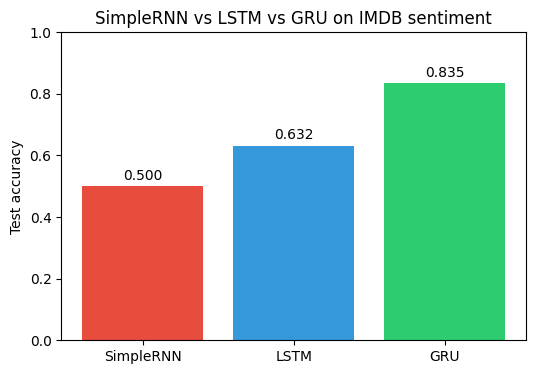

In [34]:
results = {
    'SimpleRNN': acc_rnn,
    'LSTM':      acc_lstm,
    'GRU':       acc_gru,
}

print("Test accuracy comparison")
print("-" * 30)
for name, acc in results.items():
    print(f"{name:>10}: {acc:.4f}")
print("-" * 30)
best = max(results, key=results.get)
print(f"Best model on this run: {best} ({results[best]:.4f})")

# A quick bar chart so the comparison is visible at a glance.
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.bar(results.keys(), results.values(), color=['#e74c3c', '#3498db', '#2ecc71'])
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("SimpleRNN vs LSTM vs GRU on IMDB sentiment")
for i, (name, acc) in enumerate(results.items()):
    plt.text(i, acc + 0.02, f"{acc:.3f}", ha='center')
plt.show()
